# 03 — Pixels, drawing, regions, and masks

**Level:** Beginner · 60–90 minutes  
**Prerequisites:** Read lessons 01–02: BGR, slices, copying, image files

## What you will build and learn

- Draw annotations with correct coordinates
- Build and combine binary masks
- Separate selection from the operation applied to it
- Create a reusable selective-edit pipeline

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Translate between coordinates and indexing

OpenCV drawing calls take `(x, y)`. NumPy reads pixels with `[y, x]`. Here a blank
canvas has height 300 and width 480. The selected pixel is 80 columns from the left
and 50 rows from the top. `cv2.circle` takes image, center, radius, BGR color, and
thickness. A thickness of -1 fills the shape.


Pixel at [y, x]: [  0   0 255]


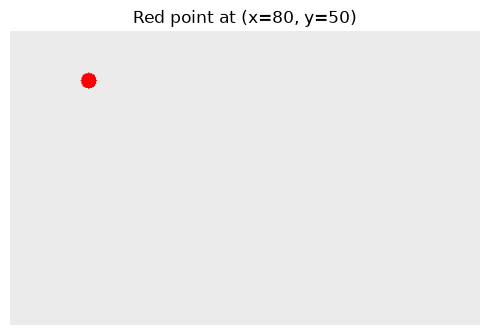

In [2]:
canvas = np.full((300, 480, 3), 235, dtype=np.uint8)
x, y = 80, 50
cv2.circle(canvas, (x, y), 8, (0, 0, 255), thickness=-1)
print("Pixel at [y, x]:", canvas[y, x])
assert np.array_equal(canvas[50, 80], [0, 0, 255])
show_images([canvas], ["Red point at (x=80, y=50)"], cols=1)


## Step 2 — Build an annotated diagram

`rectangle` takes opposite corners; `line` takes endpoints; `arrowedLine` adds an
arrowhead. These functions edit the array **in place**, so start from `.copy()` when
you want to preserve the original. `LINE_AA` blends boundary pixels for smoother
annotations; use `LINE_8` when you need a mask containing only 0 and 255.


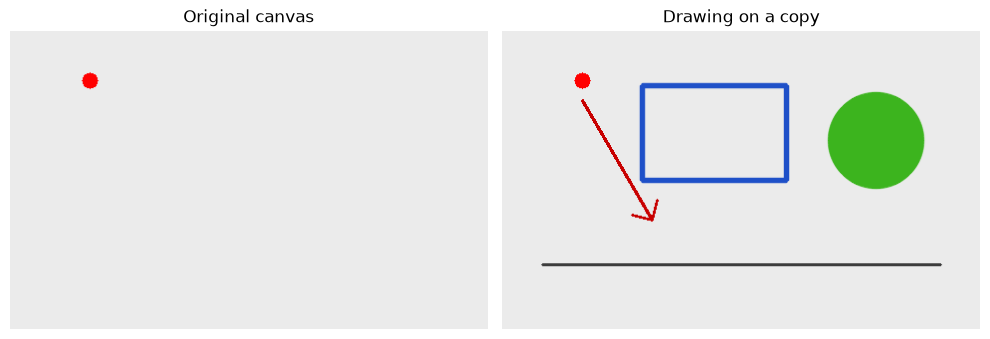

In [3]:
diagram = canvas.copy()
cv2.rectangle(diagram, (140, 55), (285, 150), (200, 80, 30), 3, lineType=cv2.LINE_AA)
cv2.circle(diagram, (375, 110), 48, (30, 180, 60), -1, lineType=cv2.LINE_AA)
cv2.line(diagram, (40, 235), (440, 235), (60, 60, 60), 2)
cv2.arrowedLine(diagram, (80, 70), (150, 190), (0, 0, 200), 2, tipLength=0.15)
show_images([canvas, diagram], ["Original canvas", "Drawing on a copy"], cols=2)


`putText` uses a **baseline origin**, not the top-left corner of the letters.
The font scale controls size, thickness controls stroke width, and `getTextSize`
estimates the width, height, and baseline needed for layout. OpenCV's built-in Hershey
fonts suit short ASCII labels; they are not a full multilingual text-layout system.


Text width, height, baseline: 200 18 8


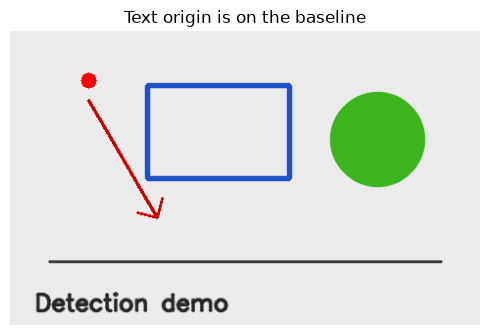

In [4]:
label = "Detection demo"
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale, thickness = 0.8, 2
(text_width, text_height), baseline = cv2.getTextSize(label, font, font_scale, thickness)
origin = (25, 285)
cv2.putText(diagram, label, origin, font, font_scale, (40, 40, 40), thickness, cv2.LINE_AA)
print("Text width, height, baseline:", text_width, text_height, baseline)
show_images([diagram], ["Text origin is on the baseline"], cols=1)


### Coordinate pitfall: inclusive drawing endpoints

NumPy slices exclude their stop index. A filled OpenCV rectangle includes its specified
endpoints. To draw exactly the slice `[y0:y1, x0:x1]`, use `(x1-1, y1-1)` as the bottom
right corner. This detail matters when testing areas or converting bounding boxes.


In [5]:
x0, y0, x1, y1 = 30, 20, 130, 80
slice_mask = np.zeros((100, 180), dtype=np.uint8)
slice_mask[y0:y1, x0:x1] = 255
drawn_mask = np.zeros_like(slice_mask)
cv2.rectangle(drawn_mask, (x0, y0), (x1 - 1, y1 - 1), 255, -1)
assert np.array_equal(slice_mask, drawn_mask)
print("Selected area:", cv2.countNonZero(slice_mask), "pixels")
assert cv2.countNonZero(slice_mask) == (x1 - x0) * (y1 - y0)


Selected area: 6000 pixels


## Step 3 — Describe where an operation is allowed

A **mask** is a single-channel selection image matching the source height and width.
For the binary masks here, 0 means unselected and 255 means selected. A mask does
not itself change the source. Keeping selection separate lets you reuse it for edits,
measurements, and visualization.


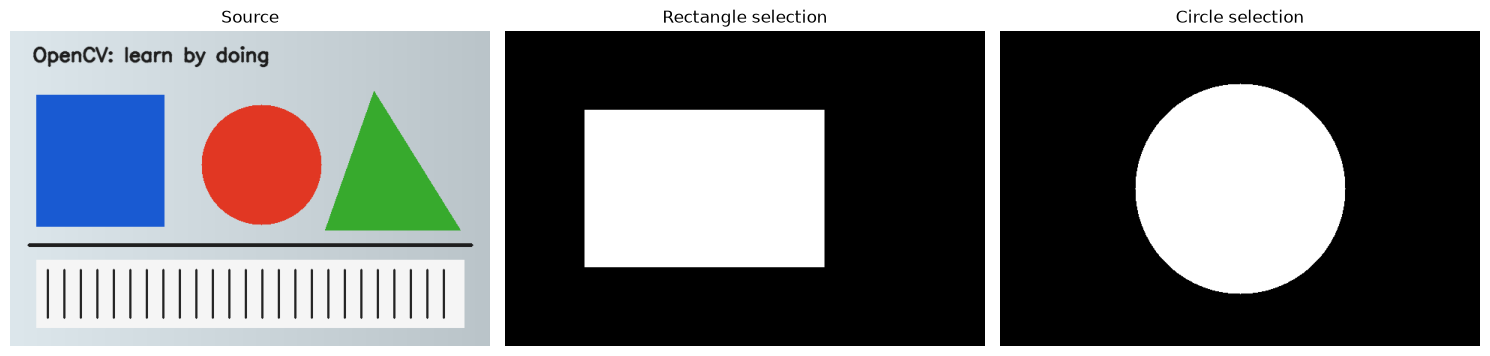

In [6]:
scene = make_scene()
h, w = scene.shape[:2]
rectangle_mask = np.zeros((h, w), dtype=np.uint8)
rectangle_mask[h // 4:3 * h // 4, w // 6:4 * w // 6] = 255
circle_mask = np.zeros((h, w), dtype=np.uint8)
cv2.circle(circle_mask, (w // 2, h // 2), min(h, w) // 3, 255, -1)
show_images([scene, rectangle_mask, circle_mask], ["Source", "Rectangle selection", "Circle selection"])
assert rectangle_mask.shape == scene.shape[:2]
assert set(np.unique(circle_mask)).issubset({0, 255})


`cv2.bitwise_and(source, source, mask=mask)` copies selected pixels to the
output and leaves the rest black. Supplying the same source twice is intentional:
the mask controls which results are retained. `countNonZero` measures selected area.


Selected 22.9% of the image


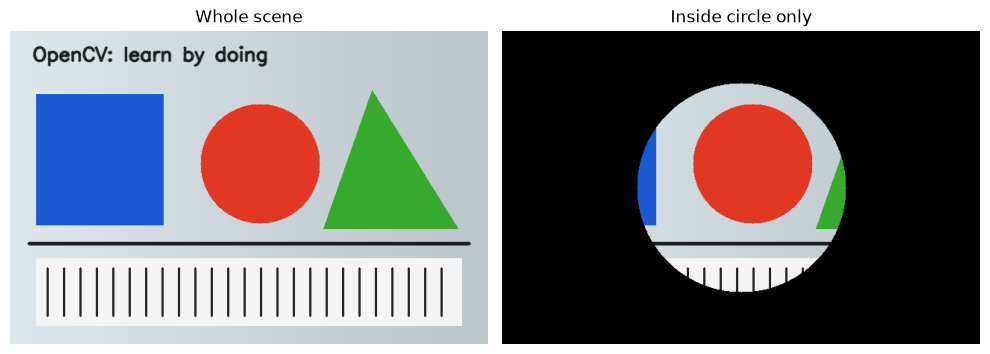

In [7]:
selected = cv2.bitwise_and(scene, scene, mask=circle_mask)
selection_fraction = cv2.countNonZero(circle_mask) / circle_mask.size
print(f"Selected {selection_fraction:.1%} of the image")
assert np.all(selected[circle_mask == 0] == 0)
assert np.array_equal(selected[circle_mask > 0], scene[circle_mask > 0])
show_images([scene, selected], ["Whole scene", "Inside circle only"], cols=2)


## Step 4 — Combine selections using logic

For binary masks, AND keeps the overlap, OR keeps either region, NOT inverts the
selection, and XOR keeps exactly one region. These meanings rely on using 0 and 255;
arbitrary grayscale values are bit patterns, not probabilities.


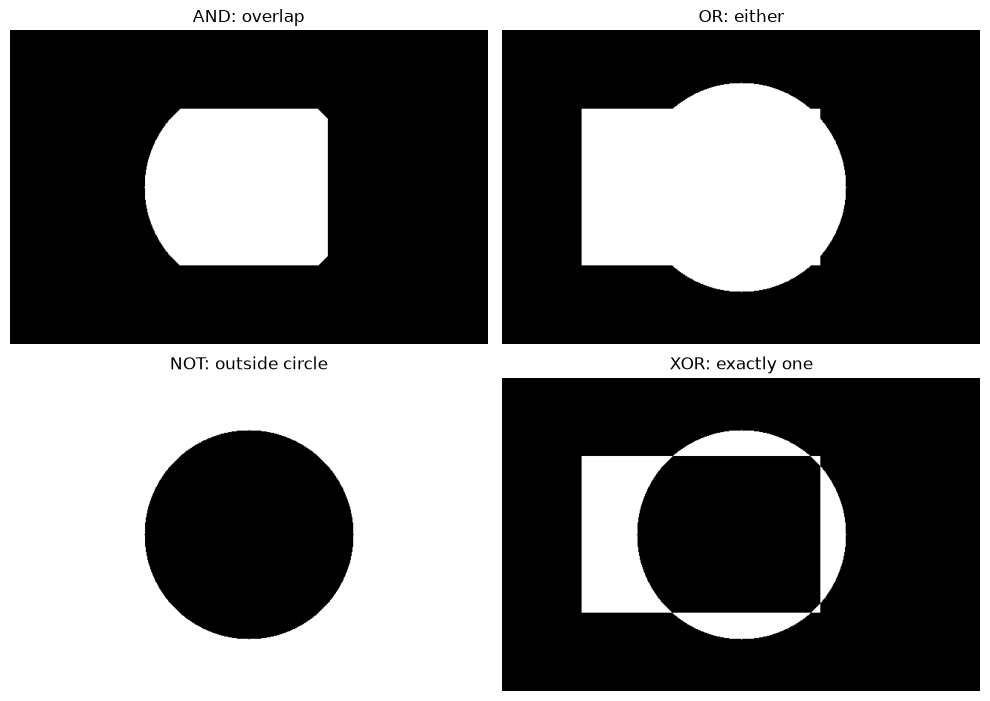

In [8]:
intersection = cv2.bitwise_and(rectangle_mask, circle_mask)
union = cv2.bitwise_or(rectangle_mask, circle_mask)
outside_circle = cv2.bitwise_not(circle_mask)
exclusive = cv2.bitwise_xor(rectangle_mask, circle_mask)
show_images([intersection, union, outside_circle, exclusive],
            ["AND: overlap", "OR: either", "NOT: outside circle", "XOR: exactly one"], cols=2)
assert cv2.countNonZero(intersection) <= cv2.countNonZero(union)
assert cv2.countNonZero(union) == (cv2.countNonZero(rectangle_mask)
    + cv2.countNonZero(circle_mask) - cv2.countNonZero(intersection))


You can also use a Boolean mask to assign a replacement color. In
`edited[mask > 0]`, NumPy selects all channels of the chosen pixels. This is useful
for marking regions and for writing pixels from another image of the same shape.


Mean B, G, R inside the circle: [149.9 153.2 197.5]


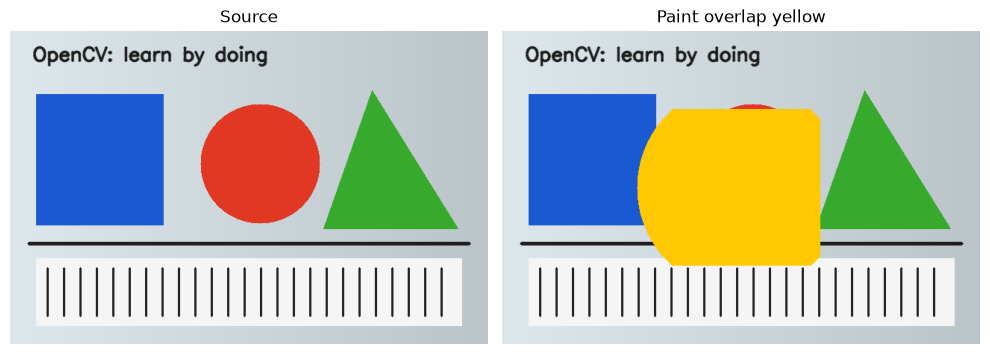

In [9]:
painted = scene.copy()
painted[intersection > 0] = (0, 200, 255)
mean_inside = cv2.mean(scene, mask=circle_mask)[:3]
print("Mean B, G, R inside the circle:", np.round(mean_inside, 1))
show_images([scene, painted], ["Source", "Paint overlap yellow"], cols=2)


### Parameter experiment: move the selection, keep the source fixed

Change the radius fraction and horizontal center. Predict the area change: a circle's
area grows approximately with the square of its radius until it meets an image edge.
Clipping at an edge is a useful reason why measured pixel area differs from a formula.


Raster area: 34621 ideal circle area: 34636


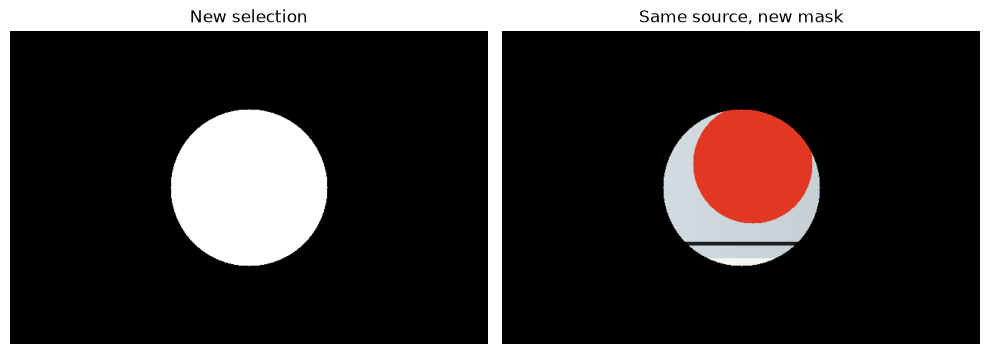

In [10]:
radius_fraction = 0.25   # Try 0.15, 0.35, and 0.55
center_x_fraction = 0.50 # Try 0.10 and 0.85
experiment_mask = np.zeros((h, w), dtype=np.uint8)
radius = max(1, round(h * radius_fraction))
center = (round(w * center_x_fraction), h // 2)
cv2.circle(experiment_mask, center, radius, 255, -1)
print("Raster area:", cv2.countNonZero(experiment_mask), "ideal circle area:", round(np.pi * radius ** 2))
show_images([experiment_mask, cv2.bitwise_and(scene, scene, mask=experiment_mask)],
            ["New selection", "Same source, new mask"], cols=2)


## Step 5 — Blend instead of replacing every pixel

`cv2.addWeighted(a, alpha, b, beta, gamma)` computes a weighted sum with an added
offset. Here `beta=1-alpha` and `gamma=0`, giving a transparent-looking overlay.
Increasing alpha gives the overlay more influence. It changes every pixel, so we copy
only the selected blended pixels back into the source.


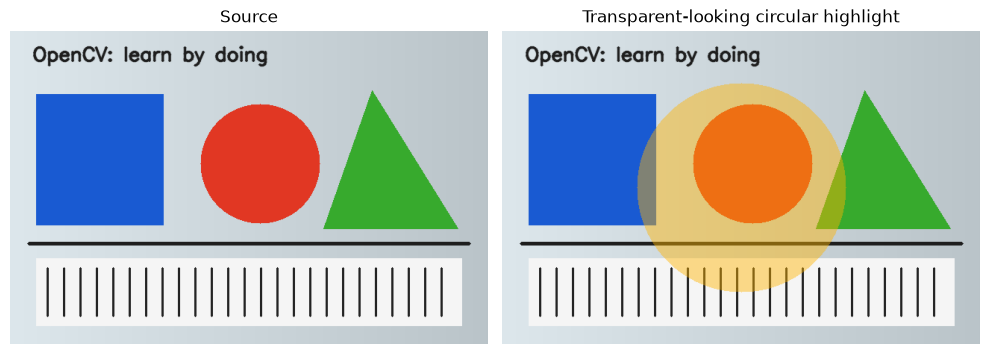

In [11]:
alpha = 0.45  # Try 0.15 and 0.80; keep it between 0 and 1.
assert 0 <= alpha <= 1
overlay = np.full_like(scene, (0, 180, 255))
blended_everywhere = cv2.addWeighted(overlay, alpha, scene, 1 - alpha, 0)
highlighted = scene.copy()
highlighted[circle_mask > 0] = blended_everywhere[circle_mask > 0]
assert np.array_equal(highlighted[circle_mask == 0], scene[circle_mask == 0])
show_images([scene, highlighted], ["Source", "Transparent-looking circular highlight"], cols=2)


A hard binary boundary can look abrupt. A **soft mask** stores weights between
0 and 1. A Gaussian blur smooths the binary mask; `[..., None]` adds a channel axis
so the same weight applies to B, G, and R. Floating-point arithmetic keeps intermediate
fractions. This is compositing, not a transparent PNG alpha channel unless we save one.


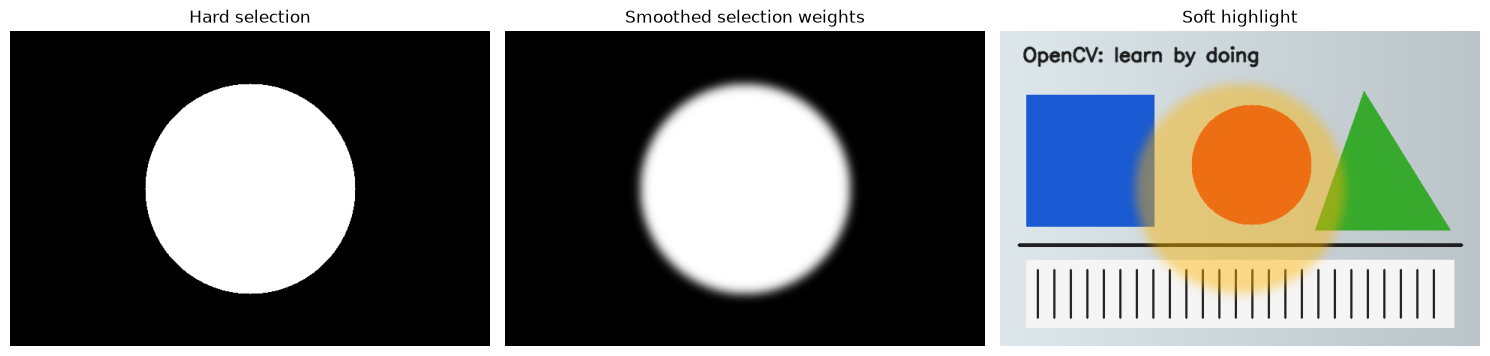

In [12]:
soft = cv2.GaussianBlur(circle_mask, (41, 41), 0).astype(np.float32) / 255.0
weights = soft[..., None]
soft_highlight = np.clip(overlay.astype(np.float32) * weights * alpha
                        + scene.astype(np.float32) * (1 - weights * alpha), 0, 255).astype(np.uint8)
show_images([circle_mask, (soft * 255).astype(np.uint8), soft_highlight],
            ["Hard selection", "Smoothed selection weights", "Soft highlight"])


## Step 6 — Mini-project: a reusable selective blur editor

Given a rectangle `(x, y, width, height)`, blur only that region and label it. A Gaussian
kernel has positive odd dimensions; a larger kernel blends a wider neighborhood. This
example is an image-editing exercise: visible blurring is not a guarantee that sensitive
information cannot be recovered. Blur the region independently to avoid editing pixels
outside the box; the region edge may still be visible.


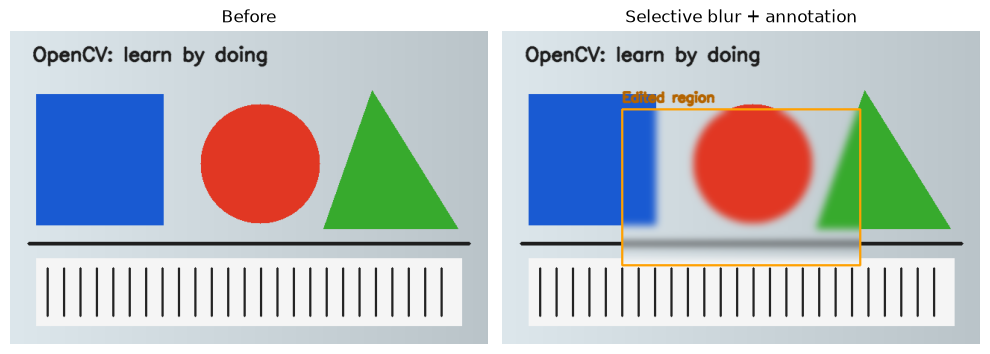

In [13]:
def blur_region(image, box, kernel_size=31):
    x, y, width, height = map(int, box)
    if not (0 <= x < image.shape[1] and 0 <= y < image.shape[0]
            and width > 0 and height > 0 and x + width <= image.shape[1]
            and y + height <= image.shape[0]):
        raise ValueError("Box must lie completely inside the image.")
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("Use a positive odd kernel size.")
    result = image.copy()
    region = image[y:y + height, x:x + width]
    result[y:y + height, x:x + width] = cv2.GaussianBlur(region, (kernel_size, kernel_size), 0)
    return result

box = (w // 4, h // 4, w // 2, h // 2)
blurred = blur_region(scene, box)
box_mask = np.zeros((h, w), dtype=np.uint8)
bx, by, bw, bh = box
box_mask[by:by + bh, bx:bx + bw] = 255
assert np.array_equal(scene[box_mask == 0], blurred[box_mask == 0])
annotated = blurred.copy()
cv2.rectangle(annotated, (bx, by), (bx + bw - 1, by + bh - 1), (0, 160, 255), 2)
cv2.putText(annotated, "Edited region", (bx, max(20, by - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 100, 180), 2, cv2.LINE_AA)
show_images([scene, annotated], ["Before", "Selective blur + annotation"], cols=2)


In [14]:
lesson_dir = ROOT / "outputs" / "03_masks"
lesson_dir.mkdir(parents=True, exist_ok=True)
save_image(lesson_dir / "selective_blur.png", annotated)
save_image(lesson_dir / "selection_mask.png", box_mask)
print("Saved project and reusable selection to:", lesson_dir)


Saved project and reusable selection to: C:\Users\Hareram ray\AI\OpencvPractical\outputs\03_masks


### Exercises — attempt first

1. Create a ring mask: retain a large disk but remove a smaller disk with the same center.
2. Change only the ring pixels to grayscale; keep all other pixels colored.
3. Measure the ring area and verify that it equals the outer disk area minus the inner
   disk area. Why should this identity hold for the rasterized masks too?


In [15]:
# Your practice area. Hint: inner must be completely contained inside outer.
# outer = np.zeros(scene.shape[:2], dtype=np.uint8)


### Worked solutions

Use AND with the inverted inner disk to remove its pixels. Convert the grayscale
result back to three channels before inserting it into a BGR image. Its channels then
have equal values, so it looks gray while matching the source array's shape.


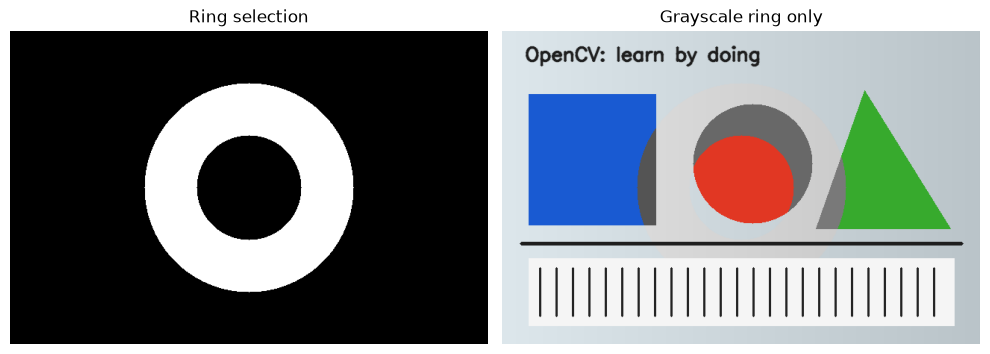

In [16]:
outer = np.zeros((h, w), dtype=np.uint8)
inner = np.zeros((h, w), dtype=np.uint8)
cv2.circle(outer, (w // 2, h // 2), h // 3, 255, -1)
cv2.circle(inner, (w // 2, h // 2), h // 6, 255, -1)
ring = cv2.bitwise_and(outer, cv2.bitwise_not(inner))
gray_bgr = cv2.cvtColor(cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)
ring_edit = scene.copy()
ring_edit[ring > 0] = gray_bgr[ring > 0]
assert cv2.countNonZero(ring) == cv2.countNonZero(outer) - cv2.countNonZero(inner)
assert np.array_equal(ring_edit[ring == 0], scene[ring == 0])
show_images([ring, ring_edit], ["Ring selection", "Grayscale ring only"], cols=2)


### Reflection

- How could an `(x, y)` / `[y, x]` mix-up appear to work on a square image?
- Why must a mask share the image's height and width, but not its channel count?
- Why do anti-aliased mask edges fail a strict assertion that values are only 0 or 255?
- Which is easier to reuse: a painted image, or an original image plus its mask?

Official references: [Drawing functions](https://docs.opencv.org/4.x/dc/da5/tutorial_py_drawing_functions.html),
[Arithmetic and masking](https://docs.opencv.org/4.x/d0/d86/tutorial_py_image_arithmetics.html).
